# California Housing: Linear, Ridge and Lasso Regression

**Goal:** predict the median house value of a district in California and compare three linear models:

- **Linear Regression** (no regularization)
- **Ridge** (L2 regularization: shrinks all coefficients)
- **Lasso** (L1 regularization: can set coefficients to exactly zero)

**Questions:**

1. Does regularization improve the prediction on this dataset?
2. Which features matter most for house prices?

**Data:** the California Housing dataset from scikit-learn (`fetch_california_housing`). It is based on the 1990 U.S. census and has one row per block group (a small district).

| Column | Meaning |
| --- | --- |
| `MedInc` | median income in the district (in 10,000 dollars) |
| `HouseAge` | median age of the houses (years) |
| `AveRooms` | average number of rooms per household |
| `AveBedrms` | average number of bedrooms per household |
| `Population` | number of people in the district |
| `AveOccup` | average number of people per household |
| `Latitude`, `Longitude` | location of the district |
| `MedHouseVal` | **target:** median house value (in 100,000 dollars) |

## 1. Load and inspect the data

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_california_housing

housing = fetch_california_housing(as_frame=True)
df = housing.frame

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   MedInc       20640 non-null  float64
 1   HouseAge     20640 non-null  float64
 2   AveRooms     20640 non-null  float64
 3   AveBedrms    20640 non-null  float64
 4   Population   20640 non-null  float64
 5   AveOccup     20640 non-null  float64
 6   Latitude     20640 non-null  float64
 7   Longitude    20640 non-null  float64
 8   MedHouseVal  20640 non-null  float64
dtypes: float64(9)
memory usage: 1.4 MB


In [2]:
df.describe().round(2)

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
count,20640.00,20640.00,20640.00,20640.00,20640.00,20640.00,20640.00,20640.00,20640.00
mean,3.87,28.64,5.43,1.10,1425.48,3.07,35.63,-119.57,2.07
std,1.90,12.59,2.47,0.47,1132.46,10.39,2.14,2.00,1.15
min,0.50,1.00,0.85,0.33,3.00,0.69,32.54,-124.35,0.15
25%,2.56,18.00,4.44,1.01,787.00,2.43,33.93,-121.80,1.20
50%,3.53,29.00,5.23,1.05,1166.00,2.82,34.26,-118.49,1.80
75%,4.74,37.00,6.05,1.10,1725.00,3.28,37.71,-118.01,2.65
max,15.00,52.00,141.91,34.07,35682.00,1243.33,41.95,-114.31,5.00


There are no missing values and all columns are numeric.

Two things stand out in the summary:

- `AveRooms` and `AveOccup` have very large maximum values (for example more than 1,000 people per household). These are probably districts with special housing such as dormitories or hotels. Linear models are sensitive to such extreme values, but I keep them because I have no information that they are errors.
- The maximum of `MedHouseVal` is exactly 5.00001. This looks like a cap.

Districts at the cap (5.00): 965


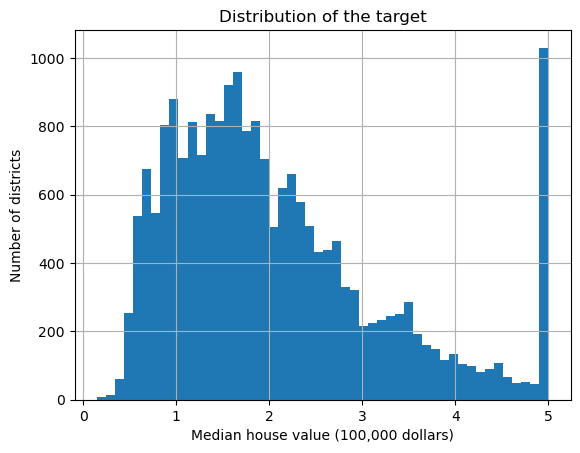

In [3]:
cap = df["MedHouseVal"].max()
print(f"Districts at the cap ({cap:.2f}): {(df['MedHouseVal'] == cap).sum()}")

df["MedHouseVal"].hist(bins=50)
plt.xlabel("Median house value (100,000 dollars)")
plt.ylabel("Number of districts")
plt.title("Distribution of the target");

Several hundred districts have the same value 5.00001: in the original data all values above 500,000 dollars were set to 500,000. The model cannot learn the real price of these expensive districts, so its predictions for very expensive areas will be too low. I keep these rows but mention this as a limitation.

## 2. Split into training and test data

I split the data **before** any scaling or model selection. The test set (20%) is used only once at the end, to compare the final models. Everything else (scaling, choosing `alpha`) is done on the training set only.

In [4]:
from sklearn.model_selection import train_test_split

X = df.drop(columns="MedHouseVal")
y = df["MedHouseVal"]
features = X.columns

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42)

print("Training set:", X_train.shape)
print("Test set:    ", X_test.shape)

Training set: (16512, 8)
Test set:     (4128, 8)


## 3. Baseline: Linear Regression

Ridge and Lasso need scaled features, because the penalty treats all coefficients the same. To keep the comparison fair, I scale the features for all three models.

I put the `StandardScaler` and the model into one `Pipeline`. This way the scaler learns the mean and standard deviation from the training data only, also inside cross-validation.

To measure the error I use the **RMSE** (root mean squared error). It is in the same unit as the target, so an RMSE of 0.7 means the predictions are off by about 70,000 dollars on average.

In [5]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.model_selection import KFold, cross_val_score

cv = KFold(n_splits=5, shuffle=True, random_state=42)


def cv_rmse(model):
    # mean RMSE over 5 cross-validation folds (training data only)
    scores = cross_val_score(model, X_train, y_train, cv=cv,
                             scoring="neg_root_mean_squared_error")
    return -scores.mean()


linear = make_pipeline(StandardScaler(), LinearRegression())
print(f"Linear Regression, cross-validated RMSE: {cv_rmse(linear):.4f}")

Linear Regression, cross-validated RMSE: 0.7205


## 4. Choose `alpha` with cross-validation

`alpha` controls how strong the regularization is: `alpha = 0` is the same as Linear Regression, a large `alpha` pushes the coefficients towards zero.

In my first version I chose `alpha` by looking at the test error. This makes the test error too optimistic, because the test data was used to make a decision. Here I try the same idea with more values, but I compare them with 5-fold cross-validation on the training data.

In [6]:
alphas = np.logspace(-3, 2, 11)   # from 0.001 to 100

ridge_rmse = []
lasso_rmse = []

for alpha in alphas:
    ridge = make_pipeline(StandardScaler(), Ridge(alpha=alpha))
    lasso = make_pipeline(StandardScaler(), Lasso(alpha=alpha, max_iter=10000))
    ridge_rmse.append(cv_rmse(ridge))
    lasso_rmse.append(cv_rmse(lasso))

alpha_results = pd.DataFrame({
    "alpha": alphas,
    "Ridge CV RMSE": ridge_rmse,
    "Lasso CV RMSE": lasso_rmse,
})
alpha_results.round(4)

,alpha,Ridge CV RMSE,Lasso CV RMSE
0,0.0010,0.7205,0.7205
1,0.0032,0.7205,0.7207
2,0.0100,0.7205,0.7239
3,0.0316,0.7205,0.7496
4,0.1000,0.7205,0.8196
5,0.3162,0.7205,0.8939
6,1.0000,0.7205,1.1562
7,3.1623,0.7205,1.1562
8,10.0000,0.7205,1.1562
9,31.6228,0.7206,1.1562


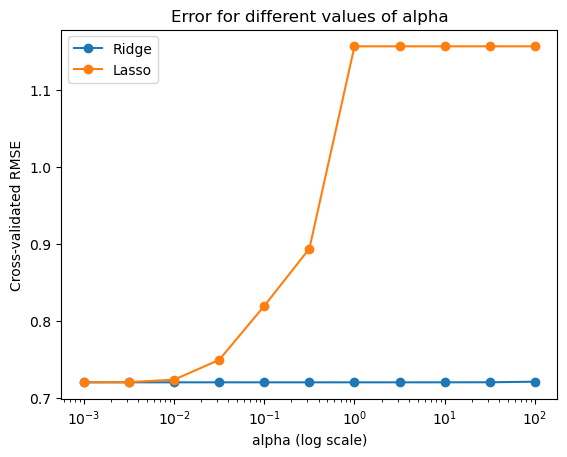

In [7]:
plt.plot(alphas, ridge_rmse, marker="o", label="Ridge")
plt.plot(alphas, lasso_rmse, marker="o", label="Lasso")
plt.xscale("log")
plt.xlabel("alpha (log scale)")
plt.ylabel("Cross-validated RMSE")
plt.title("Error for different values of alpha")
plt.legend();

In [8]:
best_alpha_ridge = alphas[np.argmin(ridge_rmse)]
best_alpha_lasso = alphas[np.argmin(lasso_rmse)]

print(f"Best alpha for Ridge: {best_alpha_ridge:.4f}")
print(f"Best alpha for Lasso: {best_alpha_lasso:.4f}")

Best alpha for Ridge: 3.1623
Best alpha for Lasso: 0.0010


- **Ridge:** the error hardly changes over the whole range. Even with `alpha = 100` the shrinkage is small, because the training set has more than 16,000 rows.
- **Lasso:** the error grows quickly with larger `alpha`. From `alpha = 1` on, Lasso sets all coefficients to zero and only predicts the average value. The best `alpha` is the smallest value I tried, so Lasso works best here with almost no regularization.

## 5. Compare the final models on the test set

Now I train each model with its chosen `alpha` on the full training set and evaluate it once on the test set. The table is built from the computed values, so it always matches the code.

In [9]:
from sklearn.metrics import mean_squared_error, r2_score

models = {
    "Linear Regression": linear,
    f"Ridge (alpha={best_alpha_ridge:.3g})":
        make_pipeline(StandardScaler(), Ridge(alpha=best_alpha_ridge)),
    f"Lasso (alpha={best_alpha_lasso:.3g})":
        make_pipeline(StandardScaler(), Lasso(alpha=best_alpha_lasso, max_iter=10000)),
}

rows = []
for name, model in models.items():
    model.fit(X_train, y_train)
    rows.append({
        "Model": name,
        "CV RMSE (train)": cv_rmse(model),
        "Test RMSE": np.sqrt(mean_squared_error(y_test, model.predict(X_test))),
        "Test MSE": mean_squared_error(y_test, model.predict(X_test)),
        "Test R²": r2_score(y_test, model.predict(X_test)),
    })

results = pd.DataFrame(rows).set_index("Model")
results.round(4)

,CV RMSE (train),Test RMSE,Test MSE,Test R²
Model,,,,
Linear Regression,0.7205,0.7456,0.5559,0.5758
Ridge (alpha=3.16),0.7205,0.7455,0.5558,0.5759
Lasso (alpha=0.001),0.7205,0.7446,0.5545,0.5769


All three models perform almost the same: the test RMSE is about 0.75, which means the predictions are off by roughly 75,000 dollars on average, and R² is about 0.58 (the models explain about 58% of the variation in house values).

The cross-validated error on the training data and the test error are also very close. So the models do **not overfit**: with 8 features and more than 16,000 rows, Linear Regression is already stable. Regularization helps when a model overfits, so here it brings almost no improvement.

## 6. Which features matter?

Because all features are scaled, the coefficients can be compared with each other: each coefficient shows how much the predicted value changes when that feature increases by one standard deviation and the other features stay the same.

In [10]:
coefs = pd.DataFrame({
    name: model[-1].coef_ for name, model in models.items()
}, index=features)

coefs.round(3).sort_values(coefs.columns[0], key=abs, ascending=False)

,Linear Regression,Ridge (alpha=3.16),Lasso (alpha=0.001)
Latitude,-0.897,-0.895,-0.886
Longitude,-0.870,-0.867,-0.858
MedInc,0.854,0.854,0.849
AveBedrms,0.339,0.338,0.326
AveRooms,-0.294,-0.294,-0.281
HouseAge,0.123,0.123,0.123
AveOccup,-0.041,-0.041,-0.040
Population,-0.002,-0.002,-0.001


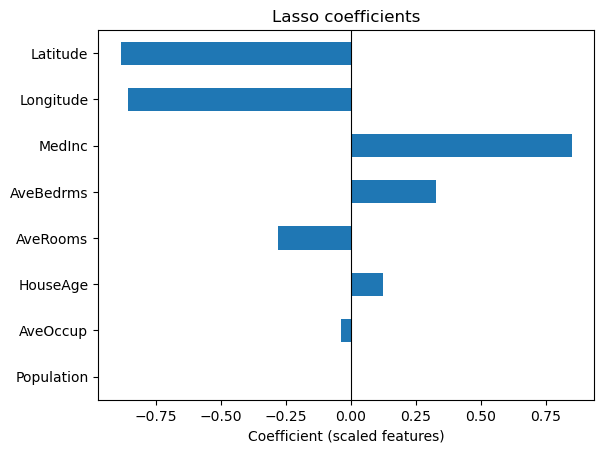

In [11]:
lasso_coefs = coefs.iloc[:, 2].sort_values(key=abs)

lasso_coefs.plot(kind="barh")
plt.axvline(0, color="black", linewidth=0.8)
plt.xlabel("Coefficient (scaled features)")
plt.title("Lasso coefficients");

In [12]:
lasso_final = models[coefs.columns[2]]
intercept = lasso_final[-1].intercept_

print(f"MedHouseVal = {intercept:.3f}")
for feature, value in lasso_coefs.sort_values(key=abs, ascending=False).items():
    if value != 0:
        print(f"    {value:+.3f} x {feature} (scaled)")

zero = lasso_coefs[lasso_coefs == 0].index.tolist()
print("\nFeatures set to zero by Lasso:", zero if zero else "none")

MedHouseVal = 2.072
    -0.886 x Latitude (scaled)
    -0.858 x Longitude (scaled)
    +0.849 x MedInc (scaled)
    +0.326 x AveBedrms (scaled)
    -0.281 x AveRooms (scaled)
    +0.123 x HouseAge (scaled)
    -0.040 x AveOccup (scaled)
    -0.001 x Population (scaled)

Features set to zero by Lasso: none


- **`MedInc`** has the largest positive effect: districts with higher income have more expensive houses.
- **`Latitude`** and **`Longitude`** have large negative coefficients. Together they describe the location: prices are higher near the coast and around the big cities (Los Angeles, San Francisco Bay Area). The two coefficients should be read together, not one by one, because a linear model can only describe location as a straight slope across the state.
- `AveRooms` and `AveBedrms` have opposite signs. The two features are strongly correlated (more rooms usually means more bedrooms), so their single coefficients are hard to interpret.
- With the chosen small `alpha`, Lasso keeps all features. In my first version with `alpha = 0.1`, Lasso kept only `MedInc`, `HouseAge` and `Latitude`, but the error was clearly higher (see the curve in section 4).

## 7. Summary

- I compared Linear Regression, Ridge and Lasso on the California Housing data, with scaling inside a pipeline and `alpha` chosen by 5-fold cross-validation on the training data.
- All three models reach a test RMSE of about 0.75 (about 75,000 dollars) and an R² of about 0.58.
- Regularization does not improve the result here, because the linear model does not overfit (training and test errors are almost the same).
- Income and location are the most important features.

**Limitations and next steps**

- House values are capped at 500,000 dollars, so the model cannot predict very expensive districts correctly.
- The relationship between location and price is not linear. Non-linear models such as a random forest or gradient boosting, or new features such as the distance to the coast, would probably reduce the error.